> **Model answers.** This is the worked-solution copy of `10-bayes.ipynb`. Answers are marked ✅; code cells have been run so you can compare outputs.

# conditional probability and Bayes' theorem [P3]

The most common Bayes slip is getting the top of the fraction right but leaving the true positives out of the bottom (18% instead of 15% in the example below). This lesson builds the formula from counts so that can't happen. It also links straight to precision and recall from `05-warmups.ipynb`.

## Lesson notes

**Plain English.** A **conditional probability** is a probability worked out *inside a smaller group*. "The chance a transaction is fraud **given** an alert fired" means: look only at the transactions that got an alert, and ask what fraction of *those* are fraud.

**Everyday vs maths English:** in everyday speech "given" means *handed over*. In probability, "given" means **"only counting the cases where this happened"**. Read the bar | as "given", or better, as "among".

**Notation (every symbol you'll see):**

| Symbol | Say it | Means (fraud example) |
|---|---|---|
| P(F) | "P of F" | probability a transaction is fraud, before you know anything else. Called the **prior** or **base rate** |
| P(not F) | "P of not F" | probability it's legit = 1 − P(F) |
| P(A \| F) | "P of A given F" | among **fraud** transactions, the fraction that get an **alert**. This is the model's **recall** (also called **sensitivity** or **true positive rate**) |
| P(A \| not F) | "P of A given not F" | among **legit** transactions, the fraction that wrongly get an alert: the **false positive rate** (FPR) |
| P(A) | "P of A" | the chance of an alert at all, counting both fraud and legit alerts. Called the **evidence** |
| P(F \| A) | "P of F given A" | among **alerts**, the fraction that are really fraud. This is the **posterior**, and it's the model's **precision** |

**Worked example: what you're given.** A bank sees **10,000** card transactions.
- **1%** are fraud: P(F) = 0.01.
- The model alerts on **90%** of fraud: P(A | F) = 0.90.
- It wrongly alerts on **5%** of legit transactions: P(A | not F) = 0.05.

**Question:** your phone buzzes with a fraud alert. What's the chance it's really fraud, P(F | A)?

**Step 1: turn the percentages into counts** (counts are easier to think with):

| Group | How to get it | Count |
|---|---|---|
| Fraud | 1% of 10,000 = 0.01 × 10,000 | **100** |
| Legit | 10,000 − 100 | **9,900** |
| Fraud **and** alert (true positives) | 90% of the 100 fraud = 0.90 × 100 | **90** |
| Fraud, no alert (false negatives) | 100 − 90 | **10** |
| Legit **and** alert (false positives) | 5% of the 9,900 legit = 0.05 × 9,900 | **495** |
| Legit, no alert (true negatives) | 9,900 − 495 | **9,405** |

Check: 90 + 10 + 495 + 9,405 = 10,000 ✓

**The same counts as a tree.** Each split multiplies by a rate. The orange boxes are all the alerts, true and false:

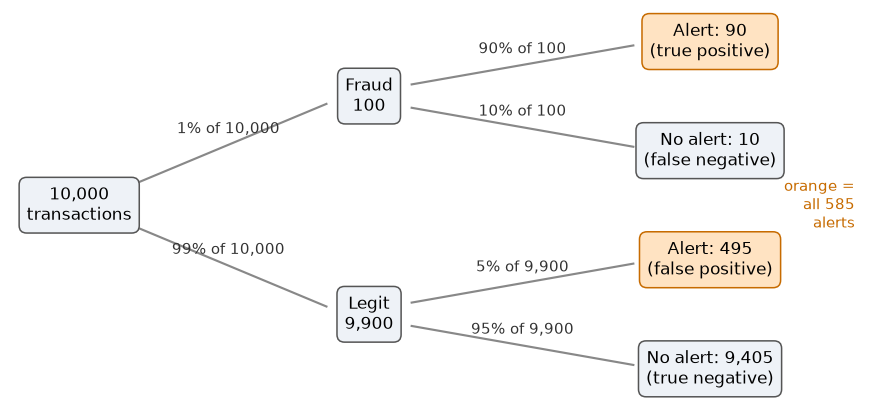

**Step 2: look only at the alerts.** That's the "given A" part: throw away everything without an alert.

| Alerts | Count |
|---|---|
| Fraud alerts (true positives) | 90 |
| Legit alerts (false positives) | 495 |
| **All alerts** | 90 + 495 = **585** |

P(F | A) = fraud alerts ÷ all alerts = 90 ÷ 585 = **0.154**, i.e. about **15%**.

So even with a model that catches 90% of fraud, **only about 1 alert in 7 is real fraud** (585 ÷ 90 = 6.5). The reason is that legit transactions outnumber fraud 99 to 1, so their small 5% false alarm rate still makes 495 false alerts, far more than the 90 real ones.

**Step 3: the same thing as a formula (Bayes' theorem).** Divide every count in step 2 by 10,000 to switch from **counts to probabilities** (decimals):

| Count | ÷ 10,000 | Probability | Formula piece |
|---|---|---|---|
| 90 | 90 ÷ 10,000 | 0.009 | P(A \| F) × P(F) = 0.90 × 0.01 |
| 495 | 495 ÷ 10,000 | 0.0495 | P(A \| not F) × P(not F) = 0.05 × 0.99 |
| 585 | 585 ÷ 10,000 | 0.0585 | P(A) = 0.009 + 0.0495 |

**Bayes' theorem:**

P(F | A) = P(A | F) × P(F) ÷ P(A)

where the bottom, **P(A), adds up every way an alert can happen**:

P(A) = P(A | F) × P(F) + P(A | not F) × P(not F) = 0.009 + 0.0495 = 0.0585

So P(F | A) = 0.009 ÷ 0.0585 = **0.154**: the same 15% as the counts.

**Why the bottom has two parts (the most common slip).** An alert can come from a fraud transaction **or** from a legit one. The bottom of the fraction must count **all** alerts, true ones (0.009) and false ones (0.0495). If you leave out the true positives you divide by 0.0495 and get 0.009 ÷ 0.0495 = 0.18, i.e. 18%, a very common wrong answer. **Rule: the top is one piece of the bottom.**

**The big trap: P(A | F) is NOT P(F | A).**

| | Means | Value here | Metric name |
|---|---|---|---|
| P(A \| F) | among frauds, how many get an alert | 0.90 | **recall** |
| P(F \| A) | among alerts, how many are fraud | 0.154 | **precision** |

Swapping them is so common it has a name: the **prosecutor's fallacy** ("the test catches 90% of criminals, so this flagged person is 90% likely guilty"). The bar flips the group you're counting in.

**Why the base rate matters so much.** Same model (recall 0.90, false positive rate 0.05), different share of fraud:

| Share that is fraud, P(F) | True alerts per 10,000 | False alerts per 10,000 | P(F \| A) |
|---|---|---|---|
| 1% | 0.90 × 100 = 90 | 0.05 × 9,900 = 495 | 90 ÷ 585 = 0.154 |
| 10% | 0.90 × 1,000 = 900 | 0.05 × 9,000 = 450 | 900 ÷ 1,350 = 0.667 |

Ten times more fraud in the mix moves precision from 15% to 67%, **without changing the model at all**. Ignoring this is called **base-rate neglect**.

**When does this apply, and when not?**
- Applies whenever you know how often the evidence shows up **in each group** (recall and false positive rate) and how big each group is (the base rate), and you want the reverse: the chance of the group, given the evidence.
- All the numbers must describe **the same population**. A model's 5% false positive rate measured on UK card payments says nothing about a new market where fraud is 5% of payments; recompute with the new base rate.
- If you already have the four counts (like a confusion matrix), you don't need the formula: just divide inside the group. The formula is the same calculation with probabilities.

**Traps to avoid:**
- **Flipping the bar:** P(A | F) ≠ P(F | A). Say both out loud as "among …" before you calculate.
- **Bottom with one part:** P(A) must include true **and** false alerts.
- **Forgetting P(not F):** the false positive rate multiplies the **legit** share (0.99), not 1 and not the fraud share.
- **Answering a % when a count was asked** (a common slip): read the question's unit first.

**Why ML cares:**
- **Precision at deployment:** a model tested on a balanced set (50% fraud) looks great, but in production fraud is 0.1%, so most alerts are false. Bayes tells you the real precision before you launch.
- **Monitoring:** if the base rate shifts (fraud surge), precision changes even though the model didn't.
- **Naive Bayes classifiers** (spam filters, early text models) are built directly on this formula.
- **Thresholds and cost:** deciding whether an alert is worth a phone call is a Bayes question: P(fraud | alert) × loss avoided vs cost of the call.

**Glossary:**
- **conditional probability** P(A | B): probability of A counting only the cases where B happened.
- **prior / base rate** P(F): how common the thing is before any evidence.
- **likelihood** P(A | F): how often the evidence appears when the thing is true (here = recall).
- **evidence** P(A): how often the evidence appears at all.
- **posterior** P(F | A): updated probability after seeing the evidence (here = precision).
- **recall / sensitivity / TPR (true positive rate)**: among real positives, the fraction flagged.
- **FPR (false positive rate)**: among real negatives, the fraction wrongly flagged.
- **precision**: among flagged, the fraction that are real positives.
- **prosecutor's fallacy**: mistaking P(A | F) for P(F | A).
- **base-rate neglect**: ignoring how rare the thing is.

## Questions
Answer these one at a time, without scrolling back to the notes first. Use the ✏️ cells if you want room for working. Show formula → numbers → answer.

**Q1 (easy).** 200 loan applicants: 50 are self-employed, and 10 of those 50 defaulted. 30 applicants defaulted in total.  
(a) P(default | self-employed)?  
(b) P(self-employed | default)?  
(c) Why are (a) and (b) different, in one sentence?

✅ **Model answer**

(a) P(default | self-employed) = 10 / 50 = **0.20**.
(b) P(self-employed | default) = 10 / 30 = **0.33**.
(c) The group after the bar is the group you **divide by**: both have the same 10 on top, but (a) divides by the 50 self-employed and (b) by the 30 defaulters.

**Q2 (easy).** A fraud model has recall 0.80. Your colleague says: "So when it alerts, there's an 80% chance it's fraud."  
(a) Write the colleague's claim and the true meaning of recall in | notation.  
(b) What extra information would you need to get the real chance an alert is fraud?

✅ **Model answer**

(a) The colleague's claim is **P(fraud | alert) = 0.80**, which is **precision**. Recall is actually **P(alert | fraud) = 0.80**: of all real fraud, 80% gets an alert.
(b) The **base rate** P(fraud) (how common fraud is) and the **false positive rate** P(alert | not fraud). Then P(fraud | alert) = 0.8 × P(F) ÷ (0.8 × P(F) + FPR × (1 − P(F))). For example, with a 1% base rate and a 5% FPR it's 0.008 / 0.0575 ≈ **14%**, nowhere near 80%.

**Q3 (medium).** Anti-money-laundering (AML) screening on **20,000** accounts. **0.5%** are laundering money. The check flags **95%** of laundering accounts and **2%** of clean accounts.  
(a) Build the four-group count table (show the working for every count).  
(b) What is P(laundering | flagged)?

✅ **Model answer**

(a) Laundering: 0.5% × 20,000 = **100**; clean: 20,000 − 100 = **19,900**.

| | Flagged | Not flagged | Total |
|---|---|---|---|
| Laundering | 100 × 0.95 = **95** | 100 − 95 = **5** | 100 |
| Clean | 19,900 × 0.02 = **398** | 19,900 − 398 = **19,502** | 19,900 |
| Total | 493 | 19,507 | 20,000 |

(b) P(laundering | flagged) = 95 / (95 + 398) = 95 / 493 = **0.193** (about 19%). About 4 in 5 flags are clean accounts.

**Q4 (medium).** The same check (95% / 2%) is now run only on accounts that staff have **already referred** as suspicious, where **20%** are laundering.  
(a) What is P(laundering | flagged) now? Use the formula this time.  
(b) The check didn't change. Why did the answer change so much?

✅ **Model answer**

(a) P(L | F) = (0.95 × 0.20) ÷ (0.95 × 0.20 + 0.02 × 0.80) = 0.19 ÷ (0.19 + 0.016) = 0.19 ÷ 0.206 = **0.922** (92%). (Out of 1,000 referred accounts: 190 true flags, 16 false flags.)
(b) The **base rate** changed from 0.5% to 20%. With far fewer clean accounts in the pool (80% instead of 99.5%), the 2% false-alarm rate produces far fewer false flags relative to the true ones. Precision depends on the base rate, not just on the model.

**Q5 (applied, interview-style).** A churn model has **85% recall** and a **10% false positive rate**. **3%** of customers churn (leave) each month. The marketing lead wants to send a **£20 voucher** to every flagged customer. Assume the voucher keeps every churner who gets it, and a kept churner is worth **£300**.  
(a) Per 10,000 customers: how many vouchers go out, and what fraction go to people who would really churn?  
(b) Is the campaign worth it? Show the £ cost and £ value, and give a one-line recommendation.

✅ **Model answer**

(a) Churners: 3% × 10,000 = 300 → flagged 0.85 × 300 = **255**. Stayers: 9,700 → flagged 0.10 × 9,700 = **970**. Vouchers = 255 + 970 = **1,225**; fraction to real churners = 255 / 1,225 = **20.8%** (about 1 in 5).
(b) Cost = 1,225 × £20 = **£24,500**. Value = 255 × £300 = **£76,500**. Net = **+£52,000**, so it's worth it *under the stated assumption*.
Recommendation: "Go ahead, but the assumption that the voucher keeps every churner is doing the heavy lifting: it only needs to keep 24,500 / 300 ≈ 82 of the 255 (32%) to break even, so pilot it on a test group first to measure that rate."

## Code it
Run the first cell, then fill every `TODO`. Each task says what you're building, the inputs, a step table with a worked example, and what it should print.

In [1]:
%matplotlib inline
import numpy as np

### C1: `bayes_posterior(prior, recall, fpr)`

**What you're building:** a function that returns P(F | A), the chance the thing is real **given** a flag, using Bayes' theorem.

**Inputs:**

| Input | What it is | Example |
|---|---|---|
| `prior` | P(F), the base rate | 0.01 (1% of transactions are fraud) |
| `recall` | P(A \| F), share of real cases that get flagged | 0.90 |
| `fpr` | P(A \| not F), the false positive rate | 0.05 |

**Steps:**

| Step | What it means | Code idea | Example result |
|---|---|---|---|
| 1 | true-alert share | `recall * prior` | 0.90 × 0.01 = 0.009 |
| 2 | false-alert share | `fpr * (1 - prior)` | 0.05 × 0.99 = 0.0495 |
| 3 | all alerts, P(A) | step 1 + step 2 | 0.009 + 0.0495 = 0.0585 |
| 4 | posterior | step 1 ÷ step 3 | 0.009 ÷ 0.0585 = 0.1538 |

**Check:** prints about `0.1538`.

In [2]:
def bayes_posterior(prior, recall, fpr):
    true_alerts = recall * prior
    false_alerts = fpr * (1 - prior)
    return true_alerts / (true_alerts + false_alerts)

print("C1:", bayes_posterior(0.01, 0.90, 0.05))   # expect about 0.1538

C1: 0.15384615384615385


### C2: `four_counts(n, prior, recall, fpr)`

**What you're building:** a function that turns the rates into the four counts (the confusion matrix) for `n` cases, returned as a dictionary. Then precision from the counts should match C1.

**Inputs:** `n` = how many cases (10,000); `prior`, `recall`, `fpr` as in C1.

**Steps:**

| Step | What it means | Code idea | Example result |
|---|---|---|---|
| 1 | how many real cases | `real = n * prior` | 10,000 × 0.01 = 100 |
| 2 | true positives | `tp = real * recall` | 100 × 0.90 = 90 |
| 3 | false negatives | `fn = real - tp` | 100 − 90 = 10 |
| 4 | false positives | `fp = (n - real) * fpr` | 9,900 × 0.05 = 495 |
| 5 | true negatives | `tn = (n - real) - fp` | 9,900 − 495 = 9,405 |
| 6 | return them | `{"tp": tp, "fn": fn, "fp": fp, "tn": tn}` | |

**Check:** prints `{'tp': 90.0, 'fn': 10.0, 'fp': 495.0, 'tn': 9405.0}` (give or take tiny float rounding) and a precision of about 0.1538.

In [3]:
def four_counts(n, prior, recall, fpr):
    real = n * prior
    tp = real * recall
    fn = real - tp
    fp = (n - real) * fpr
    tn = (n - real) - fp
    return {"tp": tp, "fn": fn, "fp": fp, "tn": tn}

c = four_counts(10_000, 0.01, 0.90, 0.05)
print("C2:", c)
print("C2 precision:", c["tp"] / (c["tp"] + c["fp"]))   # matches C1: 0.1538

C2: {'tp': 90.0, 'fn': 10.0, 'fp': 495.0, 'tn': 9405.0}
C2 precision: 0.15384615384615385


### C3: check it by simulation

**What you're building:** 100,000 pretend transactions. Each is fraud with probability 0.01. A fraud one gets an alert with probability 0.90; a legit one with probability 0.05. Then: among the alerts, what fraction are fraud?

**Steps:**

| Step | What it means | Code idea | Example result |
|---|---|---|---|
| 1 | which are fraud | `is_fraud = rng.random(100_000) < 0.01` | about 1,000 `True` |
| 2 | each one's alert chance | `np.where(is_fraud, 0.90, 0.05)` | 0.90 for fraud, 0.05 for legit |
| 3 | which get an alert | `alert = rng.random(100_000) < chance` | about 5,850 `True` |
| 4 | fraud among alerts | `is_fraud[alert].mean()` | close to 0.154 |

`np.where(condition, a, b)` picks `a` where the condition is `True` and `b` where it's `False`. Example: `np.where([True, False], 0.9, 0.05)` → `[0.9, 0.05]`.

**Check:** within about ±0.01 of 0.154.

In [4]:
rng = np.random.default_rng(42)
is_fraud = rng.random(100_000) < 0.01
chance = np.where(is_fraud, 0.90, 0.05)
alert = rng.random(100_000) < chance
print("C3:", is_fraud[alert].mean())   # close to 0.154

C3: 0.16104030313468826


### C4: the base-rate table

**What you're building:** a table showing how precision, P(F | A), changes with the base rate for the **same** model (recall 0.90, false positive rate 0.05). Use your C1 function.

**Inputs:** base rates `[0.001, 0.01, 0.05, 0.10, 0.30, 0.50]`.

**Steps:** loop over the base rates; for each, print the base rate and `round(bayes_posterior(rate, 0.90, 0.05), 3)`.

**Check:** the 0.01 row prints 0.154 and the 0.10 row prints 0.667. Then answer in a comment: **at roughly what base rate does a flag first become more likely real than not (above 0.5)?** Explain using your table.

In [5]:
for rate in [0.001, 0.01, 0.05, 0.10, 0.30, 0.50]:
    print(rate, round(bayes_posterior(rate, 0.90, 0.05), 3))

# YOUR ANSWER: between 5% (0.486, just under 0.5) and 10% (0.667), very close to 5%.
# Exactly: a flag is 50/50 when true alerts = false alerts, 0.90p = 0.05(1 - p), so
# p = 0.05 / (0.90 + 0.05) = 0.0526, a base rate of about 5.3%.

0.001 0.018
0.01 0.154
0.05 0.486
0.1 0.667
0.3 0.885
0.5 0.947
